In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import gridspec

In [3]:
data = pd.read_csv("creditcard.csv")
print(data.head())

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
print(data.describe())

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.175161e-15  3.384974e-16 -1.379537e-15  2.094852e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   1.021879e-15  1.494498e-15 -5.620335e-16  1.149614e-16 -2.414189e-15   
std    1.380247e+00  1.332271e+00  1.23709

In [5]:
fraud=data[data['Class']==1]
valid=data[data['Class']==0]
print("Number of fraudulent transactions:", len(fraud))
print("Number of valid transactions:", len(valid))
print("Percentage of fraudulent transactions:", len(fraud)/len(data)*100)
print("Percentage of valid transactions:", len(valid)/len(data)*100)

Number of fraudulent transactions: 492
Number of valid transactions: 284315
Percentage of fraudulent transactions: 0.1727485630620034
Percentage of valid transactions: 99.82725143693798


Exploring Transaction Amounts

In [6]:
print("Amount details of the fraudulent transaction")
fraud.Amount.describe()

Amount details of the fraudulent transaction


count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

In [7]:
print("details of valid transaction")
valid.Amount.describe()

details of valid transaction


count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64

Từ kết quả trên chúng ta quan sát được gian dịch gian lận có số lượng trung bình có xu hướng cao hơn, đây là điều quan trọng trong việc phát hiện gian lận

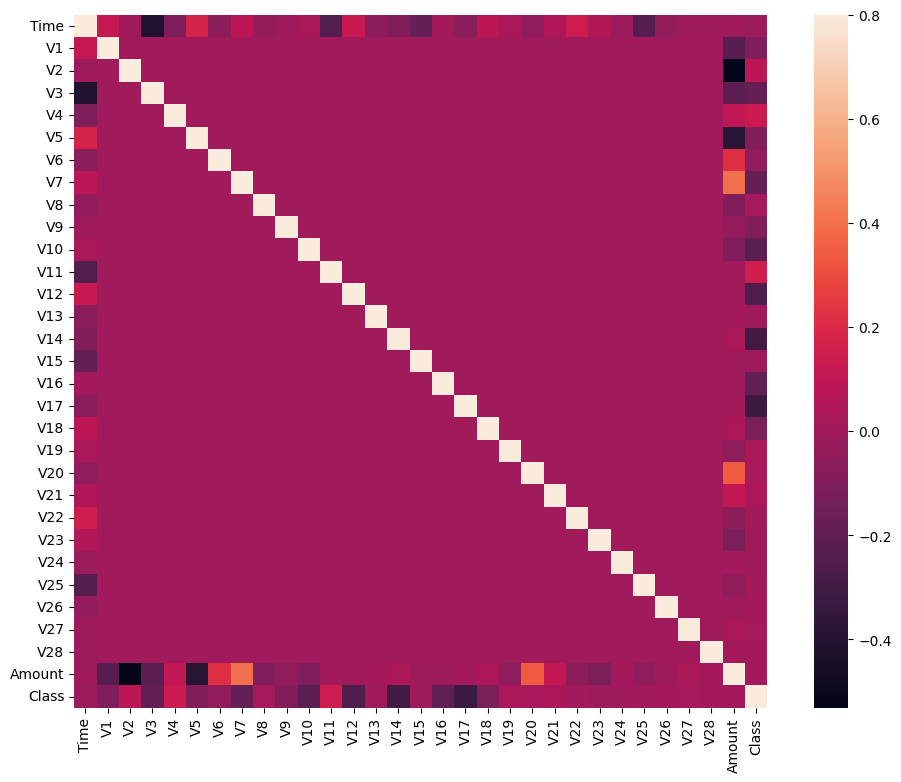

In [8]:
cormat=data.corr()
fig=plt.figure(figsize=(12,9))
sns.heatmap(cormat,vmax=.8,square=True)
plt.show()

Hầu hết các đặc trựng không tương quan mạnh với nhau nhưng có vài đặc trưng đáng chú ý như V2 và V5 có một mức độ tương quan khá tiêu cực với số lượng đặc trưng.Nó cung cấp insights giá trị trong việc how cái features đó liên quan đế số lượng giao dịch

In [9]:
X=data.drop(columns=['Class'])
Y=data['Class']
print("Shape of X:", X.shape)
print("Shape of Y:", Y.shape)


Shape of X: (284807, 30)
Shape of Y: (284807,)


In [10]:
#Converting the data into numpy array for fast training the model
xdata=X.values
xdata

array([[ 0.00000000e+00, -1.35980713e+00, -7.27811733e-02, ...,
         1.33558377e-01, -2.10530535e-02,  1.49620000e+02],
       [ 0.00000000e+00,  1.19185711e+00,  2.66150712e-01, ...,
        -8.98309914e-03,  1.47241692e-02,  2.69000000e+00],
       [ 1.00000000e+00, -1.35835406e+00, -1.34016307e+00, ...,
        -5.53527940e-02, -5.97518406e-02,  3.78660000e+02],
       ...,
       [ 1.72788000e+05,  1.91956501e+00, -3.01253846e-01, ...,
         4.45477214e-03, -2.65608286e-02,  6.78800000e+01],
       [ 1.72788000e+05, -2.40440050e-01,  5.30482513e-01, ...,
         1.08820735e-01,  1.04532821e-01,  1.00000000e+01],
       [ 1.72792000e+05, -5.33412522e-01, -1.89733337e-01, ...,
        -2.41530880e-03,  1.36489143e-02,  2.17000000e+02]],
      shape=(284807, 30))

In [11]:
ydata=Y.values

In [12]:
from sklearn.model_selection import train_test_split
X_train,x_test,Y_train,y_test=train_test_split(xdata,ydata,test_size=0.2,random_state=42)
X_train,x_val,Y_train,y_val=train_test_split(X_train,Y_train,test_size=0.25,random_state=42)

In [13]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scale=scaler.fit_transform(X_train)
X_val_scale=scaler.transform(x_val)

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

In [15]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
lr=LogisticRegression(max_iter=1000,random_state=42)
rf.fit(X_train_scale,Y_train)
lr.fit(X_train_scale,Y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [16]:
y_val_pred_rf=rf.predict(X_val_scale)
y_val_pred_lr=lr.predict(X_val_scale)

In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score,classification_report,confusion_matrix
def evaluate_model(y_true,y_pred,model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    
    print(f"Evaluation Metrics for {model_name}:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))
    
    confusion = confusion_matrix(y_true, y_pred)
    print("Confusion Matrix:")
    print(confusion)

In [18]:
evaluate_model(y_val,y_val_pred_rf,"Random Forest")
evaluate_model(y_val,y_val_pred_lr,"Logistic Regression")


Evaluation Metrics for Random Forest:
Accuracy: 0.9996
Precision: 0.9661
Recall: 0.7308
F1 Score: 0.8321

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56884
           1       0.97      0.73      0.83        78

    accuracy                           1.00     56962
   macro avg       0.98      0.87      0.92     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56882     2]
 [   21    57]]
Evaluation Metrics for Logistic Regression:
Accuracy: 0.9993
Precision: 0.8364
Recall: 0.5897
F1 Score: 0.6917

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56884
           1       0.84      0.59      0.69        78

    accuracy                           1.00     56962
   macro avg       0.92      0.79      0.85     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56875     9]


Ta nhận thấy rằng: Số lượng TP(Dự đoán đúng giao dịch bình thường) của RandomForest là 56882 còn Logistic Regression là 56875, thấp hơn RandomForest. Tương tự: FN(21)< FN(32) đánh giá mức độ bỏ sót gian lận randomforest ít hơn. FP(2)< FP(9) đánh giá mức độ báo động nhầm. Và cuối cùng là TP(57)> TP(36) đánh giá mức độ chính xác giao dịch gian lận.


### Model Evaluation and Comparison
Sau khi huấn luyện hai mô hình Random Forest và Logistic Regression trên tập Training,tiến hành đánh giá và so sánh hiệu suất của chúng trên tập Validation.

**1. Random Forest**
Mô hình đạt Accuracy 99,96%, Precision 96,61%, Recall 73,08% và F1-score 83,21%.

Đặc biệt, mô hình phát hiện chính xác 57/78 giao dịch gian lận, chỉ bỏ sót 21 giao dịch và đưa ra 2 cảnh báo nhầm đối với các giao dịch bình thường. Điều này cho thấy Random Forest có khả năng phát hiện Fraud tương đối tốt, đồng thời duy trì tỷ lệ cảnh báo nhầm thấp.

**2. Logistic Regression**
Mô hình đạt Accuracy 99,93%, Precision 83,64%, Recall 58,97% và F1-score 69,17%.

Mặc dù đạt Accuracy cao, Logistic Regression chỉ phát hiện được 46/78 giao dịch gian lận, bỏ sót 32 giao dịch và đưa ra 9 cảnh báo nhầm. Điều này cho thấy khả năng phát hiện Fraud của mô hình còn hạn chế so với Random Forest.

**3. Model Selection**
Dựa trên kết quả đánh giá, Random Forest thể hiện hiệu suất tốt hơn Logistic Regression trên cả bốn chỉ số Accuracy, Precision, Recall và F1-score.

Đặc biệt, Random Forest có Recall cao hơn, giúp phát hiện thêm 11 giao dịch gian lận và hạn chế 11 trường hợp bỏ sót so với Logistic Regression.
Vì vậy, Random Forest được lựa chọn làm mô hình phù hợp hơn để tiếp tục phát triển và tối ưu hóa trong các giai đoạn tiếp theo.

Đối với Fraud Detection, Recall(mức đánh giá tỉ lệ gian lận được phát hiện) rất quan trọng vì giao dịch gian lận bị bỏ sót có thể gây thiệt hại tài chính.

In [19]:
X_train_final=np.concatenate((X_train_scale,X_val_scale),axis=0)
Y_train_final=np.concatenate((Y_train,y_val),axis=0)

In [21]:
scaler_final=StandardScaler()
X_train_final_scale=scaler_final.fit_transform(X_train_final)
X_test_final_scale=scaler_final.transform(x_test)

In [22]:
final_model=RandomForestClassifier(n_estimators=100,random_state=42)
final_model.fit(X_train_final_scale,Y_train_final)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [23]:
y_test_pred=final_model.predict(X_test_final_scale)

In [24]:
evaluate_model(y_test,y_test_pred,"Random forest(Final model after investigate)")

Evaluation Metrics for Random forest(Final model after investigate):
Accuracy: 0.9994
Precision: 0.8916
Recall: 0.7551
F1 Score: 0.8177

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56864
           1       0.89      0.76      0.82        98

    accuracy                           1.00     56962
   macro avg       0.95      0.88      0.91     56962
weighted avg       1.00      1.00      1.00     56962

Confusion Matrix:
[[56855     9]
 [   24    74]]


Recall from 0.6308 up to 0.7551